This notebook will serve to generate bathymetric surfaces from hydrographic soundings. As of 27 MAY 26, I am thinking of making this an ablation study where I increase the complexity of the SVGP. At first we start with a base SVGP, then add ARD to the kernel to adjust for anisotropic soundings, and then introduce an MLP for kernel warping to adjust for non-stationarity in the soundings.

In [1]:
%reload_ext autoreload
%autoreload 2
import os
import sys
sys.path.insert(0, os.path.abspath('../src'))
import pandas as pd
import geopandas as gpd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import contextily as cx
from shapely import contains_xy
from scipy.spatial import Delaunay
import verde as vd

import tqdm
import rasterio
from rasterio.warp import transform_bounds
from rasterio.transform import from_origin
import torch
import gpytorch
from torch.utils.data import TensorDataset, DataLoader

from gpytorch.models import ApproximateGP
from gpytorch.variational import CholeskyVariationalDistribution
from gpytorch.variational import VariationalStrategy
from gpytorch.constraints import Interval, GreaterThan
from gpytorch.priors import GammaPrior

# Check device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

Using device: cuda
GPU: NVIDIA GeForce RTX 4070
Memory: 12.5 GB


In [2]:
WORK_DIR = Path('/mnt/teamgroup/AutoDBM/Public')
MBES = WORK_DIR / 'Multibeam_Validation_Points_For_Distribution'
SBES = WORK_DIR / 'Synthetic_Singlebeam_Surveys_For_Distribution'
CRS = pd.read_csv(WORK_DIR / 'survey_CRS_list.csv')

mbes = list((WORK_DIR / 'Multibeam_Validation_Points_For_Distribution').glob('*.csv'))
sbes = list((WORK_DIR / 'Synthetic_Singlebeam_Surveys_For_Distribution').glob('*.csv'))
crs_data = WORK_DIR / 'survey_CRS_list.csv'

geojson = Path(os.getcwd()).parent / 'shapefiles' / 'National_Channel_Framework_-6742069550782745925.geojson'
ncf = gpd.read_file(geojson)

In [3]:
# TODO: Go through and build a dataset off these 30 which include congressionally authorized depths
# this would allow us to better estimate dredge cuts and copmare across the interpolation methods

# NOTE: authorized depths probably vary between the individual reaches within each area


# Build a boundary catalog from SurveyJob layers, then match each survey to the best boundary by SurveyId
data_pairs = {}

def _norm(s):
    return "".join(ch for ch in str(s).upper() if ch.isalnum())

def _tokens(s):
    return {t for t in str(s).upper().replace("-", "_").split("_") if t}

# 1) Read all boundary candidates once
boundary_catalog = []
for gdb_file in WORK_DIR.glob("*/*.gdb"):
    try:
        sj = gpd.read_file(gdb_file, layer="SurveyJob")
    except Exception:
        continue

    if "SurveyId" not in sj.columns or sj.empty:
        continue

    # keep one record per SurveyId (first occurrence)
    for sid, grp in sj.groupby("SurveyId", dropna=True):
        boundary_catalog.append({
            "survey_id": str(sid),
            "survey_norm": _norm(sid),
            "survey_tokens": _tokens(sid),
            "gdb_file": gdb_file,
            "boundary": grp.copy()
        })

# 2) Match each survey from CRS table to best boundary
for _, items in pd.read_csv(crs_data).iterrows():
    survey = items["Survey"]

    sbes_match = [p for p in sbes if survey in str(p)]
    mbes_match = [p for p in mbes if survey in str(p)]
    if not sbes_match or not mbes_match:
        print(f"Missing SBES/MBES file for: {survey}")
        continue

    s_norm = _norm(survey)
    s_tokens = _tokens(survey)

    # exact normalized SurveyId match first
    exact = [c for c in boundary_catalog if c["survey_norm"] == s_norm]

    if exact:
        best = exact[0]
    else:
        # fallback: token overlap score
        scored = []
        for c in boundary_catalog:
            inter = len(s_tokens & c["survey_tokens"])
            denom = max(1, len(s_tokens))
            score = inter / denom
            scored.append((score, c))
        scored.sort(key=lambda x: x[0], reverse=True)
        best = scored[0][1] if scored and scored[0][0] > 0 else None

    if best is None:
        print(f"No boundary found for: {survey}")
        continue

    boundary = best["boundary"]
    data_pairs[survey] = [
        sbes_match[0],
        mbes_match[0],
        boundary,
    ]

    print(f"{survey} -> {best['survey_id']} ({best['gdb_file'].name})")

AK_08_WES_20160318_CS_FULL -> AK_08_WES_20160318_CS (AK_08_WES_20160318_CS.gdb)
BR_02_JEC_20260211_CS -> BR_02_JEC_20260211_CS (BR_02_JEC_20260211_CS.gdb)
CB_02_CB2_20260202_CS_A -> CB_02_CB2_20260202_CS (CB_02_CB2_20260202_CS.gdb)
CC_05_HLQ_20260205_XC -> CC_05_HLQ_20260205_XC (CC_05_HLQ_20260205_XC.gdb)
CH_02_CHL_20220210_CS_FULL -> CH_02_CHL_20220210_CS (CH_02_CHL_20220210_CS.gdb)
CL_02_UDS_20260305_CS_A -> CL_02_UDS_20260305_CS (CL_02_UDS_20260305_CS.gdb)
CR_ND_BL5_20220301_CS_102_103_SORT -> CR_ND_BL5_20220301_CS_102_103_SORT (CR_ND_BL5_20220301_CS_102_103_SORT.gdb)
DU_02_EWW_20260211_CS_E_12_6_1_67 -> DU_02_EWW_20260211_CS_E_12_6_1_67 (DU_02_EWW_20260211_CS_E_12_6_1_67.gdb)
FR_6A_SCL_20240401_CS -> FR_6A_SCL_20240401_CS (FR_6A_SCL_20240401_CS.gdb)
GH_03_COC_20251202_CS_E_5_13_439 -> GH_03_COC_20251202_CS_E_5_13_439 (GH_03_COC_20251202_CS_E_5_13_439.gdb)
GW_68_CSL_20250909_CS_3X3_A -> GW_68_CSL_20250909_CS_3X3 (GW_68_CSL_20250909_CS_3X3.gdb)
IL_LA_MVR_20251118_CS_14001420_25D_A ->

BR_02_JEC_20260211_CS


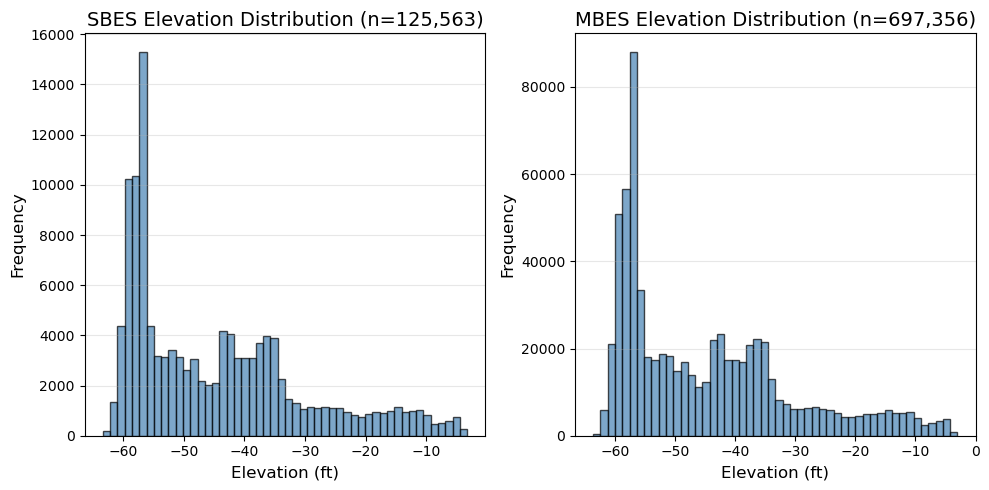


SBES Elevation Statistics (n=125,563):
  Mean: -44.64 ft
  Std: 14.39 ft
  Min: -63.35 ft
  Max: -3.24 ft

MBES Elevation Statistics (n=697,356):
  Mean: -44.88 ft
  Std: 14.22 ft
  Min: -63.61 ft
  Max: -3.01 ft


In [16]:
# NOTE: Following are on wsl
# 3, 10, 12, 13, 14, 16, 17, 18, 19, 20, 22, 25, 26, 29

# NOTE: 24 is huge, may need to do it on ms-a1 since more ram available to cpu. Like 1.5 million points for the initial full singlebeam

# survey = list(data_pairs.keys())[24]
survey = "BR_02_JEC_20260211_CS"
print(survey)
# survey = "CL_02_UDS_20260305_CS_A"    # UDS example for figures

test_pair = data_pairs[survey]
sbes_data = pd.read_csv(test_pair[0])
mbes_data = pd.read_csv(test_pair[1])
boundary = test_pair[2]
data_crs = boundary.crs

sbes_gdf = gpd.GeoDataFrame(
        sbes_data.copy(),
        geometry=gpd.points_from_xy(sbes_data["X_ft"], sbes_data["Y_ft"]),
        crs=data_crs
    )

mbes_gdf = gpd.GeoDataFrame(
        mbes_data.copy(),
        geometry=gpd.points_from_xy(mbes_data["X_ft"], mbes_data["Y_ft"]),
        crs=data_crs
    )

OUT_DIR = WORK_DIR / survey
os.makedirs(OUT_DIR, exist_ok=True)

sbes_x = sbes_gdf.X_ft
sbes_y = sbes_gdf.Y_ft
sbes_z = sbes_gdf.Elevation_ft * -1

mbes_x = mbes_gdf.X_ft
mbes_y = mbes_gdf.Y_ft
mbes_z = mbes_gdf.Elevation_ft * -1

fig, ax = plt.subplots(1,2, figsize=(10, 5))

# Histogram for sbes_z
ax[0].hist(sbes_z, bins=50, color='steelblue', edgecolor='black', alpha=0.7)
ax[0].set_xlabel('Elevation (ft)', fontsize=12)
ax[0].set_ylabel('Frequency', fontsize=12)
ax[0].set_title(f'SBES Elevation Distribution (n={len(sbes_z):,})', fontsize=14)
ax[0].grid(axis='y', alpha=0.3)

# Histogram for mbes_z
ax[1].hist(mbes_z, bins=50, color='steelblue', edgecolor='black', alpha=0.7)
ax[1].set_xlabel('Elevation (ft)', fontsize=12)
ax[1].set_ylabel('Frequency', fontsize=12)
ax[1].set_title(f'MBES Elevation Distribution (n={len(mbes_z):,})', fontsize=14)
ax[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Print summary statistics
print(f"\nSBES Elevation Statistics (n={len(sbes_z):,}):")
print(f"  Mean: {np.mean(sbes_z):.2f} ft")
print(f"  Std: {np.std(sbes_z):.2f} ft")
print(f"  Min: {np.min(sbes_z):.2f} ft")
print(f"  Max: {np.max(sbes_z):.2f} ft")

print(f"\nMBES Elevation Statistics (n={len(mbes_z):,}):")
print(f"  Mean: {np.mean(mbes_z):.2f} ft")
print(f"  Std: {np.std(mbes_z):.2f} ft")
print(f"  Min: {np.min(mbes_z):.2f} ft")
print(f"  Max: {np.max(mbes_z):.2f} ft")

In [17]:
class GPModel(ApproximateGP):
    def __init__(self, inducing_points, train_x, train_y):
        variational_distribution = CholeskyVariationalDistribution(inducing_points.size(0))
        variational_strategy = VariationalStrategy(
            self, inducing_points, variational_distribution,
            learn_inducing_locations=True,
        )
        super().__init__(variational_strategy)

        # TODO: Try out different mean functions
        # Maybe even try some of the means with first and second derivatives?
        
        # self.mean_module = gpytorch.means.ZeroMean()
        self.mean_module = gpytorch.means.ConstantMean()      # NOTE: this one is probably redundant since pre-processing has been done to confirm a mean of zero
        # self.mean_module = gpytorch.means.LinearMean(input_size=2)

        ext = (train_x.max(dim=0).values - train_x.min(dim=0).values).detach().cpu()
        dmin, dmax = float(ext.min()), float(ext.max())

        target_variance = float(train_y.var())
        prior_concentration = 2.0
        prior_rate = prior_concentration / target_variance

        self.covar_short = gpytorch.kernels.ScaleKernel(
            gpytorch.kernels.MaternKernel(
                nu=1.5, ard_num_dims=2,
                lengthscale_constraint=Interval(dmin * 0.005, dmin * 0.10),
            ),
            outputscale_prior=GammaPrior(prior_concentration, prior_rate)
        )
        self.covar_long = gpytorch.kernels.ScaleKernel(
            gpytorch.kernels.MaternKernel(
                nu=2.5, ard_num_dims=2,
                lengthscale_constraint=Interval(dmin * 0.10, dmax * 0.50),  
            ),
            outputscale_prior=GammaPrior(prior_concentration, prior_rate)
        )

        self.covar_short.base_kernel.lengthscale = dmin * 0.03
        self.covar_long.base_kernel.lengthscale = dmin * 0.20
        self.covar_short.outputscale = 0.1
        self.covar_long.outputscale = 0.1

    def forward(self, x):
        mean_x = self.mean_module(x)
        covar_x = self.covar_short(x) + self.covar_long(x)
        return gpytorch.distributions.MultivariateNormal(mean_x, covar_x)

def init_inducing_points(X, n_inducing=3000):
    from sklearn.cluster import MiniBatchKMeans

    # Use MiniBatchKMeans on CPU for speed, then move back to the active device
    kmeans = MiniBatchKMeans(n_clusters=n_inducing, batch_size=10000, n_init=3, random_state=42)
    kmeans.fit(X.detach().cpu().numpy())
    centers = torch.tensor(kmeans.cluster_centers_, dtype=torch.float32)

    # Tiny perturbation helps avoid near-duplicate inducing locations that can destabilize Kzz
    centers = centers + 1e-5 * torch.randn_like(centers)
    return centers.to(X.device)

In [18]:
point_spacings = [4, 8, 12, 16, 20, 50, 100]
trackline_spacings = [1, 2, 4, 8, 12, 16, 20]

num_transects = max(sbes_gdf['Transect_ID']) - min(sbes_gdf['Transect_ID'])  # how many transects are available in the singlebeam survey?

for itspace, tspace in enumerate(trackline_spacings):  # loop through the different transect spacings
    track_spacing = tspace * 25

    transects_to_use = list(np.arange(min(sbes_gdf['Transect_ID']), min(sbes_gdf['Transect_ID']) + num_transects + 1, tspace))  # transect indices that we will use to achieve the desired spacing

    # Downsample the synthetic singlebeam data to only contain the desired transect spacing.
    transect_id_temp = list(sbes_gdf['Transect_ID'])  # transect ID for each row of the singlebeam dataframe
    use_row = [(id in transects_to_use) for id in transect_id_temp]
    sbes_gdf_this_tspace = sbes_gdf[use_row].reset_index(drop=True)
    del (use_row, transect_id_temp)

    # Remove any points used to create this set of transects from the multibeam validation data.
    mbes_gdf_this_tspace = mbes_gdf[~mbes_gdf['Used_to_create_transect'].isin(transects_to_use)].reset_index(drop=True)

    for ipspace, pspace in enumerate(point_spacings):  # loop through the different point spacings
        pt_spacing = 2 * pspace
        if (OUT_DIR / f'SVGP_depth_{track_spacing}_{pt_spacing}.tif').exists():
            print(f"Rasters have already been generated for track spacing of {track_spacing} and sounding spacing of {pt_spacing}")
            continue
        else:

            along_length_temp = np.array(sbes_gdf_this_tspace['Length_along_transect_ft'])
            along_length_temp = np.round(along_length_temp)  # some of them are decimals??? I have no clue why Arc did that.
            use_row = [(np.mod(thislength, pspace) == 0) for thislength in along_length_temp]
            singlebeam_this_tspace_pspace = sbes_gdf_this_tspace[use_row].reset_index(drop=True)  # this is the final set of points that we will use to create the TIN.
            del (along_length_temp, use_row)
    
            sbes_x = singlebeam_this_tspace_pspace.X_ft
            sbes_y = singlebeam_this_tspace_pspace.Y_ft
            sbes_z = singlebeam_this_tspace_pspace.Elevation_ft * -1
    
            chain = vd.Chain([
                ("reduce", vd.BlockMean(spacing=50)),   # 50ft spacing reuction for fitting the spline
                ("spline", vd.Spline(damping=1e-4)),
            ])
            xy_raw = np.column_stack([sbes_x, sbes_y])
            
            chain.fit((xy_raw[:, 0], xy_raw[:, 1]), sbes_z)
            trend_pred = chain.predict((xy_raw[:, 0], xy_raw[:, 1]))   # evaluate at full resolution
            residuals = sbes_z - trend_pred
            
            residuals_norm = (residuals - np.mean(residuals)) / np.std(residuals)
    
            grid_res = 10.0 
            
            # 1. Train on the full dataset
            X_all = torch.as_tensor(xy_raw, dtype=torch.float32)
            y_all = torch.as_tensor(residuals_norm, dtype=torch.float32)
            
            # Standardize
            x_mean = X_all.mean(0)
            x_std = X_all.std(0).clamp_min(1e-6)
            X_all_scaled = (X_all - x_mean) / x_std
            
            if torch.cuda.is_available():
                X_all_scaled = X_all_scaled.cuda().float()
                y_all = y_all.cuda().float()
            # xy_raw = np.asarray(xy_raw, dtype=np.float32)
            x_min, x_max = float(xy_raw[:, 0].min()), float(xy_raw[:, 0].max())
            y_min, y_max = float(xy_raw[:, 1].min()), float(xy_raw[:, 1].max())
            
            nx = int(np.ceil((x_max - x_min) / grid_res)) + 1
            ny = int(np.ceil((y_max - y_min) / grid_res)) + 1
            x_grid = np.linspace(x_min, x_min + (nx - 1) * grid_res, nx, dtype=np.float32)
            y_grid = np.linspace(y_min, y_min + (ny - 1) * grid_res, ny, dtype=np.float32)
            
            transform = from_origin(
                x_min - grid_res / 2,
                y_max + grid_res / 2,
                grid_res, grid_res
            )
            
            grid_xx, grid_yy = np.meshgrid(x_grid, y_grid)  # shape (ny, nx) by default
            grid_points = torch.stack([
                torch.tensor(grid_xx.flatten(), dtype=torch.float32),
                torch.tensor(grid_yy.flatten(), dtype=torch.float32)
            ], dim=1)
            
            grid_points_s = (grid_points - x_mean.cpu()) / x_std.cpu()
    
            all_train_dataset = TensorDataset(X_all_scaled, y_all)
            
            all_train_loader = DataLoader(
                all_train_dataset,
                batch_size=2048, 
                shuffle=True,
                num_workers=0 # Keep at 0 since data is already on GPU
            )
    
            X_unique = torch.unique(X_all_scaled, dim=0)
    
            num_inducing = min(5000, X_unique.size(0))
            inducing_points = init_inducing_points(X_unique, num_inducing)
    
            train_x_all, train_y_all = all_train_loader.dataset.tensors   # (N,2) coords, (N,) depths
    
            model = GPModel(inducing_points=inducing_points,
                            train_x=train_x_all, train_y=train_y_all)
    
            likelihood = gpytorch.likelihoods.GaussianLikelihood(
                noise_constraint=GreaterThan(1e-3), 
                noise_prior=GammaPrior(concentration=2.0, rate=4.65) 
            )
    
            if torch.cuda.is_available():
                model = model.cuda()
                likelihood = likelihood.cuda()
    
            variational_params = set(model.variational_strategy._variational_distribution.parameters())
            hyper_params = [p for p in model.parameters() if p not in variational_params] + \
                           list(likelihood.parameters())
    
            variational_ngd_optimizer = gpytorch.optim.NGD(
                model.variational_strategy._variational_distribution.parameters(),
                num_data=y_all.size(0),
                lr=0.01, 
            )
    
            hyperparameter_optimizer = torch.optim.Adam(hyper_params, lr=0.01)
    
            num_epochs = 50
    
            model.train()
            likelihood.train()
            
            optimizer = torch.optim.Adam([
                {'params': model.parameters()},
                {'params': likelihood.parameters()},
            ], lr=0.01)
            
            # Our loss object. We're using the VariationalELBO
            mll = gpytorch.mlls.VariationalELBO(likelihood, model, num_data=y_all.size(0))
            
            epochs_iter = tqdm.notebook.tqdm(range(num_epochs), desc="Epoch")
            with gpytorch.settings.cholesky_jitter(1e-4), gpytorch.settings.variational_cholesky_jitter(1e-4), gpytorch.settings.cholesky_max_tries(10):
                for i in epochs_iter:
                    # Within each iteration, we will go over each minibatch of data
                    minibatch_iter = tqdm.notebook.tqdm(all_train_loader, desc="Minibatch", leave=False)
                    for x_batch, y_batch in minibatch_iter:
                        optimizer.zero_grad()
                        output = model(x_batch)
                        loss = -mll(output, y_batch)
                        minibatch_iter.set_postfix(loss=loss.item())
                        loss.backward()
                        optimizer.step()
    
            model.eval()
            likelihood.eval()
            pred_means = []
            pred_stds = []
            
            with torch.no_grad(), gpytorch.settings.fast_pred_var():
                for i in range(0, grid_points_s.size(0), 2048):
                    batch = grid_points_s[i:i+2048].cuda() if torch.cuda.is_available() else grid_points_s[i:i+2048]
                    # preds = likelihood(model(batch))
                    preds = model(batch)
                    pred_means.append(preds.mean.cpu())
                    pred_stds.append(preds.stddev.cpu())
            
            pred_means = torch.cat(pred_means)
            pred_stds = torch.cat(pred_stds)
            
            # Convert back to real units
            z_grid = pred_means * np.std(residuals) + np.mean(residuals)
            z_uncertainty = pred_stds * np.std(residuals)
            
            trend_pred_grid = chain.predict((grid_points[:, 0].numpy(), grid_points[:, 1].numpy()))
            z_grid_true = z_grid.numpy() + trend_pred_grid
            
            # Reshape to 2D grid
            z_surface = z_grid_true.reshape(grid_xx.shape)
            z_unc_surface = z_uncertainty.reshape(grid_xx.shape)
            
            grid_np = grid_points.numpy()
            polygon_mask = contains_xy((boundary).union_all(), grid_np[:, 0], grid_np[:, 1])
            delaunay_hull = Delaunay(xy_raw)
            delaunay_flat_mask = delaunay_hull.find_simplex(grid_np) >= 0
            mask = delaunay_flat_mask & polygon_mask
            
            # Apply mask to predictions.
            z_grid_masked = z_grid_true
            z_unc_masked = z_uncertainty
            z_grid_masked[~mask] = np.nan
            z_unc_masked[~mask] = np.nan
            
            # Reshape back to 2D arrays aligned with transform/from_origin.
            z_surface_masked = z_grid_masked.reshape(grid_xx.shape)
            z_unc_surface_masked = z_unc_masked.reshape(grid_xx.shape)
            
            z_raster = np.flipud(z_surface_masked).astype(np.float32)
            z_unc_raster = np.flipud(z_unc_surface_masked).astype(np.float32)
    
            meta = {
                'driver': 'GTiff',
                'height': z_raster.shape[0],
                'width': z_raster.shape[1],
                'count': 1,
                'dtype': 'float32',
                'crs': data_crs,
                'transform': transform,
                'nodata': -9999,
                'tiled': True,
                'blockxsize': 512,
                'blockysize': 512,
                'compress': 'deflate',
                'predictor': 3,
                'zlevel': 6
            }
            
            with rasterio.open(OUT_DIR / f'SVGP_depth_{track_spacing}_{pt_spacing}.tif', 'w', **meta) as dst:
                dst.write(z_raster, 1)
                dst.build_overviews([2, 4, 8, 16, 32], rasterio.enums.Resampling.average)
            
            with rasterio.open(OUT_DIR / f'SVGP_uncertainty_{track_spacing}_{pt_spacing}.tif', 'w', **meta) as dst:
                dst.write(z_unc_raster, 1)
                dst.build_overviews([2, 4, 8, 16, 32], rasterio.enums.Resampling.average)

Rasters have already been generated for track spacing of 25 and sounding spacing of 8
Rasters have already been generated for track spacing of 25 and sounding spacing of 16
Rasters have already been generated for track spacing of 25 and sounding spacing of 24
Rasters have already been generated for track spacing of 25 and sounding spacing of 32
Rasters have already been generated for track spacing of 25 and sounding spacing of 40
Rasters have already been generated for track spacing of 25 and sounding spacing of 100
Rasters have already been generated for track spacing of 25 and sounding spacing of 200
Rasters have already been generated for track spacing of 50 and sounding spacing of 8
Rasters have already been generated for track spacing of 50 and sounding spacing of 16
Rasters have already been generated for track spacing of 50 and sounding spacing of 24
Rasters have already been generated for track spacing of 50 and sounding spacing of 32
Rasters have already been generated for tra

In [20]:
# NOTE: Completely processed surveys should have 49 SVGP depth rasters (and 49 uncertainty rasters)
# some may have 50 if the entire point cloud was processed

# TODO: get the data from WSL

local_results = []
wsl_results = []

for survey in list(data_pairs.keys()):
    OUT_DIR = WORK_DIR / survey
    if len(list(OUT_DIR.glob("SVGP_depth*.tif"))) < 49:
        wsl_results.append(survey)
    else:
        local_results.append(survey)
    # print(survey, len(list(OUT_DIR.glob("SVGP_depth*.tif"))))

In [21]:
len(local_results)

16

In [22]:
len(wsl_results)

14

In [ ]:
# writing SVGP function for easier implementation.
# would need to just e able to feed in the sbes points since we are iteratively sampling them down to sparser transect and sounding spacings

# 1. feed raw points in
# 2. detrend with verde chain
# 3. generate prediction grid
# 4. 

In [ ]:
# point_spacings = [4, 8, 12, 16, 20, 50, 100]
# trackline_spacings = [1, 2, 4, 8, 12, 16, 20]

point_spacings = [4]
trackline_spacings = [1]

num_transects = max(sbes_gdf['Transect_ID']) - min(sbes_gdf['Transect_ID'])  # how many transects are available in the singlebeam survey?

for itspace, tspace in enumerate(trackline_spacings):  # loop through the different transect spacings
    track_spacing = tspace * 25

    transects_to_use = list(np.arange(min(sbes_gdf['Transect_ID']), min(sbes_gdf['Transect_ID']) + num_transects + 1, tspace))  # transect indices that we will use to achieve the desired spacing

    # Downsample the synthetic singlebeam data to only contain the desired transect spacing.
    transect_id_temp = list(sbes_gdf['Transect_ID'])  # transect ID for each row of the singlebeam dataframe
    use_row = [(id in transects_to_use) for id in transect_id_temp]
    sbes_gdf_this_tspace = sbes_gdf[use_row].reset_index(drop=True)
    del (use_row, transect_id_temp)

    # Remove any points used to create this set of transects from the multibeam validation data.
    mbes_gdf_this_tspace = mbes_gdf[~mbes_gdf['Used_to_create_transect'].isin(transects_to_use)].reset_index(drop=True)

    for ipspace, pspace in enumerate(point_spacings):  # loop through the different point spacings
        pt_spacing = 2 * pspace

        along_length_temp = np.array(sbes_gdf_this_tspace['Length_along_transect_ft'])
        along_length_temp = np.round(along_length_temp)  # some of them are decimals??? I have no clue why Arc did that.
        use_row = [(np.mod(thislength, pspace) == 0) for thislength in along_length_temp]
        singlebeam_this_tspace_pspace = sbes_gdf_this_tspace[use_row].reset_index(drop=True)  # this is the final set of points that we will use to create the TIN.
        del (along_length_temp, use_row)

        sbes_x = singlebeam_this_tspace_pspace.X_ft
        sbes_y = singlebeam_this_tspace_pspace.Y_ft
        sbes_z = singlebeam_this_tspace_pspace.Elevation_ft * -1

fig, ax = plt.subplots(1,1, figsize=(10, 5))

# Histogram for sbes_z
ax.hist(sbes_z, bins=50, color='steelblue', edgecolor='black', alpha=0.7)
ax.set_xlabel('Elevation (ft)', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)
ax.set_title(f'SBES Elevation Distribution (n={len(sbes_z):,})', fontsize=14)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Print summary statistics
print(f"\nSBES Elevation Statistics (n={len(sbes_z):,}):")
print(f"  Mean: {np.mean(sbes_z):.2f} ft")
print(f"  Std: {np.std(sbes_z):.2f} ft")
print(f"  Min: {np.min(sbes_z):.2f} ft")
print(f"  Max: {np.max(sbes_z):.2f} ft")

In [ ]:
# TODO: implement a verde spline and look to see if it will better zero-mean the data compared to normalization
import verde as vd

chain = vd.Chain([
    ("reduce", vd.BlockMean(spacing=50)),   # 50ft spacing reuction for fitting the spline
    ("spline", vd.Spline(damping=1e-4)),
])
xy_raw = np.column_stack([sbes_x, sbes_y])

chain.fit((xy_raw[:, 0], xy_raw[:, 1]), sbes_z)
trend_pred = chain.predict((xy_raw[:, 0], xy_raw[:, 1]))   # evaluate at full resolution
residuals = sbes_z - trend_pred

residuals_norm = (residuals - np.mean(residuals)) / np.std(residuals)

fig, ax = plt.subplots(figsize=(10, 5))

# Histogram for residuals_norm
ax.hist(residuals_norm, bins=20, color='steelblue', edgecolor='black', alpha=0.7)
ax.set_xlabel('Detrended Standardized Depth', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)
ax.set_title(f'Detrended Standardized Depth Distribution (n={len(residuals_norm):,})', fontsize=14)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Print summary statistics
print(f"Detrended Standardized Depth Statistics (n={len(residuals_norm):,}):")
print(f"  Mean: {np.mean(residuals_norm):.2f}")
print(f"  Std: {np.std(residuals_norm):.2f}")
print(f"  Min: {np.min(residuals_norm):.2f}")
print(f"  Max: {np.max(residuals_norm):.2f}")

## Develop spatial GP for generating surfaces

In [ ]:
# should be 10 ft spatial resolution for the outputs
grid_res = 10.0 

# 1. Train on the full dataset
X_all = torch.as_tensor(xy_raw, dtype=torch.float32)
y_all = torch.as_tensor(residuals_norm, dtype=torch.float32)

# Standardize
x_mean = X_all.mean(0)
x_std = X_all.std(0).clamp_min(1e-6)
X_all_scaled = (X_all - x_mean) / x_std

if torch.cuda.is_available():
    X_all_scaled = X_all_scaled.cuda().float()
    y_all = y_all.cuda().float()
xy_raw = np.asarray(xy_raw, dtype=np.float32)
x_min, x_max = float(xy_raw[:, 0].min()), float(xy_raw[:, 0].max())
y_min, y_max = float(xy_raw[:, 1].min()), float(xy_raw[:, 1].max())

nx = int(np.ceil((x_max - x_min) / grid_res)) + 1
ny = int(np.ceil((y_max - y_min) / grid_res)) + 1
x_grid = np.linspace(x_min, x_min + (nx - 1) * grid_res, nx, dtype=np.float32)
y_grid = np.linspace(y_min, y_min + (ny - 1) * grid_res, ny, dtype=np.float32)

transform = from_origin(
    x_min - grid_res / 2,
    y_max + grid_res / 2,
    grid_res, grid_res
)

grid_xx, grid_yy = np.meshgrid(x_grid, y_grid)  # shape (ny, nx) by default
grid_points = torch.stack([
    torch.tensor(grid_xx.flatten(), dtype=torch.float32),
    torch.tensor(grid_yy.flatten(), dtype=torch.float32)
], dim=1)

grid_points_s = (grid_points - x_mean.cpu()) / x_std.cpu()

In [ ]:
all_train_dataset = TensorDataset(X_all_scaled, y_all)
# all_train_loader = DataLoader(all_train_dataset, batch_size=1024, shuffle=True)

all_train_loader = DataLoader(
    all_train_dataset,
    batch_size=2048, 
    shuffle=True,
    num_workers=0 # Keep at 0 since data is already on GPU
)

In [ ]:
class GPModel(ApproximateGP):
    def __init__(self, inducing_points, train_x, train_y):
        variational_distribution = CholeskyVariationalDistribution(inducing_points.size(0))
        variational_strategy = VariationalStrategy(
            self, inducing_points, variational_distribution,
            learn_inducing_locations=True,
        )
        super().__init__(variational_strategy)

        # TODO: Try out different mean functions
        # Maybe even try some of the means with first and second derivatives?
        
        # self.mean_module = gpytorch.means.ZeroMean()
        self.mean_module = gpytorch.means.ConstantMean()      # NOTE: this one is probably redundant since pre-processing has been done to confirm a mean of zero
        # self.mean_module = gpytorch.means.LinearMean(input_size=2)

        ext = (train_x.max(dim=0).values - train_x.min(dim=0).values).detach().cpu()
        dmin, dmax = float(ext.min()), float(ext.max())

        target_variance = float(train_y.var())
        prior_concentration = 2.0
        prior_rate = prior_concentration / target_variance

        self.covar_short = gpytorch.kernels.ScaleKernel(
            gpytorch.kernels.MaternKernel(
                nu=1.5, ard_num_dims=2,
                lengthscale_constraint=Interval(dmin * 0.005, dmin * 0.10),
            ),
            outputscale_prior=GammaPrior(prior_concentration, prior_rate)
        )
        self.covar_long = gpytorch.kernels.ScaleKernel(
            gpytorch.kernels.MaternKernel(
                nu=2.5, ard_num_dims=2,
                lengthscale_constraint=Interval(dmin * 0.10, dmax * 0.50),  
            ),
            outputscale_prior=GammaPrior(prior_concentration, prior_rate)
        )

        self.covar_short.base_kernel.lengthscale = dmin * 0.03
        self.covar_long.base_kernel.lengthscale = dmin * 0.20
        self.covar_short.outputscale = 0.1
        self.covar_long.outputscale = 0.1

    def forward(self, x):
        mean_x = self.mean_module(x)
        covar_x = self.covar_short(x) + self.covar_long(x)
        return gpytorch.distributions.MultivariateNormal(mean_x, covar_x)

In [ ]:
# TODO: Make the number of inducing points an input when pushing to HPC

from sklearn.cluster import MiniBatchKMeans

X_unique = torch.unique(X_all_scaled, dim=0)
# TODO: refine this so that if there are less than 3000 points, an exact GP is used instead of an SVGP
# TODO: also, maybe have it increase for huge datasets. 

# 2. Smarter Inducing Point Initialization (Run once)
# This ensures m points cover the survey area better than random sampling
def init_inducing_points(X, n_inducing=3000):
    # Use MiniBatchKMeans on CPU for speed, then move back to the active device
    kmeans = MiniBatchKMeans(n_clusters=n_inducing, batch_size=10000, n_init=3, random_state=42)
    kmeans.fit(X.detach().cpu().numpy())
    centers = torch.tensor(kmeans.cluster_centers_, dtype=torch.float32)

    # Tiny perturbation helps avoid near-duplicate inducing locations that can destabilize Kzz
    centers = centers + 1e-5 * torch.randn_like(centers)
    return centers.to(X.device)

num_inducing = min(5000, X_unique.size(0))
inducing_points = init_inducing_points(X_unique, num_inducing)

In [ ]:
# model = GPModel(inducing_points=inducing_points)

train_x_all, train_y_all = all_train_loader.dataset.tensors   # (N,2) coords, (N,) depths

model = GPModel(inducing_points=inducing_points,
                train_x=train_x_all, train_y=train_y_all)

# gamma prior noise since we don't have TPU and we may assume that greater depths will result in higher noise
likelihood = gpytorch.likelihoods.GaussianLikelihood(
    noise_constraint=GreaterThan(1e-3), 
    noise_prior=GammaPrior(concentration=2.0, rate=4.65) 
)

if torch.cuda.is_available():
    model = model.cuda()
    likelihood = likelihood.cuda()

variational_params = set(model.variational_strategy._variational_distribution.parameters())
hyper_params = [p for p in model.parameters() if p not in variational_params] + \
               list(likelihood.parameters())

variational_ngd_optimizer = gpytorch.optim.NGD(
    model.variational_strategy._variational_distribution.parameters(),
    num_data=y_all.size(0),
    lr=0.01, 
)

hyperparameter_optimizer = torch.optim.Adam(hyper_params, lr=0.01)

In [ ]:
num_epochs = 50

model.train()
likelihood.train()

optimizer = torch.optim.Adam([
    {'params': model.parameters()},
    {'params': likelihood.parameters()},
], lr=0.01)

# Our loss object. We're using the VariationalELBO
mll = gpytorch.mlls.VariationalELBO(likelihood, model, num_data=y_all.size(0))

epochs_iter = tqdm.notebook.tqdm(range(num_epochs), desc="Epoch")
with gpytorch.settings.cholesky_jitter(1e-4), gpytorch.settings.variational_cholesky_jitter(1e-4), gpytorch.settings.cholesky_max_tries(10):
    for i in epochs_iter:
        # Within each iteration, we will go over each minibatch of data
        minibatch_iter = tqdm.notebook.tqdm(all_train_loader, desc="Minibatch", leave=False)
        for x_batch, y_batch in minibatch_iter:
            optimizer.zero_grad()
            output = model(x_batch)
            loss = -mll(output, y_batch)
            minibatch_iter.set_postfix(loss=loss.item())
            loss.backward()
            optimizer.step()

In [ ]:
# TODO: Try and use scipy.spatial.Delaunay to clip prediction grid to the same extent as the TIN using the grid generated during delaunay triangulation

model.eval()
likelihood.eval()
pred_means = []
pred_stds = []

with torch.no_grad(), gpytorch.settings.fast_pred_var():
    for i in range(0, grid_points_s.size(0), 2048):
        batch = grid_points_s[i:i+2048].cuda() if torch.cuda.is_available() else grid_points_s[i:i+2048]
        # preds = likelihood(model(batch))
        preds = model(batch)
        pred_means.append(preds.mean.cpu())
        pred_stds.append(preds.stddev.cpu())

pred_means = torch.cat(pred_means)
pred_stds = torch.cat(pred_stds)

# Convert back to real units
z_grid = pred_means * np.std(residuals) + np.mean(residuals)
z_uncertainty = pred_stds * np.std(residuals)

trend_pred_grid = chain.predict((grid_points[:, 0].numpy(), grid_points[:, 1].numpy()))
z_grid_true = z_grid.numpy() + trend_pred_grid

# Reshape to 2D grid
z_surface = z_grid_true.reshape(grid_xx.shape)
z_unc_surface = z_uncertainty.reshape(grid_xx.shape)

grid_np = grid_points.numpy()
polygon_mask = contains_xy((boundary).union_all(), grid_np[:, 0], grid_np[:, 1])
delaunay_hull = Delaunay(xy_raw)
delaunay_flat_mask = delaunay_hull.find_simplex(grid_np) >= 0
# delaunay_mask = delaunay_flat_mask.reshape(grid_xx.shape)
mask = delaunay_flat_mask & polygon_mask

# Apply mask to predictions.
z_grid_masked = z_grid_true
z_unc_masked = z_uncertainty
z_grid_masked[~mask] = np.nan
z_unc_masked[~mask] = np.nan

# Reshape back to 2D arrays aligned with transform/from_origin.
z_surface_masked = z_grid_masked.reshape(grid_xx.shape)
z_unc_surface_masked = z_unc_masked.reshape(grid_xx.shape)
 
z_raster = np.flipud(z_surface_masked).astype(np.float32)
z_unc_raster = np.flipud(z_unc_surface_masked).astype(np.float32)

In [ ]:
# export bathymetric surface

meta = {
    'driver': 'GTiff',
    'height': z_raster.shape[0],
    'width': z_raster.shape[1],
    'count': 1,
    'dtype': 'float32',
    'crs': data_crs,
    'transform': transform,
    'nodata': -9999,
    'tiled': True,
    'blockxsize': 512,
    'blockysize': 512,
    'compress': 'deflate',
    'predictor': 3,
    'zlevel': 6
}

with rasterio.open(OUT_DIR / 'SVGP_depth.tif', 'w', **meta) as dst:
    dst.write(z_raster, 1)
    dst.build_overviews([2, 4, 8, 16, 32], rasterio.enums.Resampling.average)

with rasterio.open(OUT_DIR / 'SVGP_uncertainty.tif', 'w', **meta) as dst:
    dst.write(z_unc_raster, 1)
    dst.build_overviews([2, 4, 8, 16, 32], rasterio.enums.Resampling.average)

In [ ]:
survey_polygons_3857 = boundary.to_crs(epsg=3857)
ncf_polygons_3857 = ncf.to_crs(epsg=3857)

# Reproject raster extent from survey CRS to Web Mercator.
x_min_3857, y_min_3857, x_max_3857, y_max_3857 = transform_bounds(
    data_crs, "EPSG:3857", x_min, y_min, x_max, y_max
)
extent_3857 = [x_min_3857, x_max_3857, y_min_3857, y_max_3857]

# plot predictions and prediction uncertainty
fig, axes = plt.subplots(1, 2, figsize=(18, 9), dpi=150)

im1 = axes[0].imshow(
    np.flipud(z_raster), origin="lower", extent=extent_3857,
    cmap="viridis", alpha=0.7, zorder=2
)

ncf_polygons_3857.plot(ax=axes[0], facecolor='none', edgecolor='red',
                       linewidth=2, zorder=3)
cx.add_basemap(axes[0], source=cx.providers.OpenStreetMap.Mapnik,
               crs="EPSG:3857", zorder=1)
axes[0].set_xlim(extent_3857[0], extent_3857[1])
axes[0].set_ylim(extent_3857[2], extent_3857[3])
axes[0].set_title("SVGP Interpolation (Depth)")
axes[0].set_xlabel("Easting (m, Web Mercator)")
axes[0].set_ylabel("Northing (m, Web Mercator)")
fig.colorbar(im1, ax=axes[0], label="Depth (ft)", shrink=0.8)


im2 = axes[1].imshow(
    np.flipud(z_unc_raster), origin="lower", extent=extent_3857,
    cmap="magma_r", alpha=0.7, zorder=2
)

ncf_polygons_3857.plot(ax=axes[1], facecolor='none', edgecolor='red',
                       linewidth=2, zorder=3)
cx.add_basemap(axes[1], source=cx.providers.OpenStreetMap.Mapnik,
               crs="EPSG:3857", zorder=1)
axes[1].set_xlim(extent_3857[0], extent_3857[1])
axes[1].set_ylim(extent_3857[2], extent_3857[3])
axes[1].set_title("SVGP Predictive Uncertainty (1σ)")
axes[1].set_xlabel("Easting (m, Web Mercator)")
axes[1].set_ylabel("Northing (m, Web Mercator)")
fig.colorbar(im2, ax=axes[1], label="Uncertainty (ft)", shrink=0.8)

plt.tight_layout()
plt.show()